### Étape 1: Chargement et Préparation des Données

In [1]:
# Je monte Google Drive pour accéder aux données
from google.colab import drive
drive.mount('/content/gdrive')

import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Je définis les chemins de base pour les données
base_path = '/content/gdrive/My Drive/data'
train_dir = os.path.join(base_path, 'train')
validation_dir = os.path.join(base_path, 'validation')

# Je définis la taille des images (par exemple 64x64 pixels)
IMG_SIZE = 64

# Je crée une fonction pour charger les images et les étiquettes
def load_images_from_folder(folder, max_images_per_category=40):
    images = []
    labels = []
    image_paths = []
    # J'ai mis à jour la label_map pour correspondre aux noms de dossiers 'cats' et 'dogs'
    label_map = {'cats': 0, 'dogs': 1}

    # Je parcours chaque élément dans le dossier principal (qui doit contenir les sous-dossiers de catégories)
    for label_name in os.listdir(folder):
        label_path = os.path.join(folder, label_name)
        # Je vérifie que c'est bien un répertoire et que le nom de la catégorie est dans notre map
        if os.path.isdir(label_path) and label_name in label_map:
            # Je parcours les images dans chaque dossier de catégorie, en limitant le nombre spécifié
            for img_name in os.listdir(label_path)[:max_images_per_category]:
                img_path = os.path.join(label_path, img_name)
                try:
                    img = cv2.imread(img_path)
                    if img is not None:
                        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                        images.append(img)
                        labels.append(label_map[label_name])
                        image_paths.append(img_path)
                    else:
                        print(f"Impossible de charger l'image: {img_path}")
                except Exception as e:
                    print(f"Erreur lors du traitement de l'image {img_path}: {e}")
        elif os.path.isdir(label_path) and label_name not in label_map:
            print(f"Attention: Catégorie '{label_name}' trouvée mais non définie dans label_map. Ignorée.")

    return np.array(images), np.array(labels), image_paths, list(label_map.keys())

# Je charge les données d'entraînement
print("Chargement des images d'entraînement...")
X_train_raw, y_train_raw, _, _ = load_images_from_folder(train_dir, max_images_per_category=40)

# Je charge les données de validation (pour l'évaluation finale et l'animation)
print("Chargement des images de validation...")
X_val_raw, y_val_raw, validation_image_paths, label_map_names = load_images_from_folder(validation_dir, max_images_per_category=10)

# Je convertis le label_map_names en dictionnaire pour une utilisation ultérieure
label_map = {i: name for i, name in enumerate(label_map_names)}

print(f"Nombre d'images d'entraînement: {len(X_train_raw)}")
print(f"Nombre d'images de validation: {len(X_val_raw)}")

Mounted at /content/gdrive
Chargement des images d'entraînement...
Chargement des images de validation...
Attention: Catégorie 'chiens' trouvée mais non définie dans label_map. Ignorée.
Attention: Catégorie 'chats' trouvée mais non définie dans label_map. Ignorée.
Nombre d'images d'entraînement: 80
Nombre d'images de validation: 20


In [2]:
# Je normalise les valeurs des pixels (0-255) à une échelle de 0-1
X_train_normalized = X_train_raw.astype('float32') / 255.0
X_val_normalized = X_val_raw.astype('float32') / 255.0

# J'aplatis les images pour le réseau de neurones (64*64*3 = 12288 caractéristiques par image)
X_train_flattened = X_train_normalized.reshape(X_train_normalized.shape[0], -1)
X_val_flattened = X_val_normalized.reshape(X_val_normalized.shape[0], -1)

# J'applique la mise à l'échelle (StandardScaler) aux données aplaties
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flattened)
X_val_scaled = scaler.transform(X_val_flattened)

# Je transforme les étiquettes en format attendu (si nécessaire, comme un tableau 2D)
y_train = y_train_raw.reshape(-1, 1)
y_val = y_val_raw.reshape(-1, 1)

print(f"Forme de X_train_scaled: {X_train_scaled.shape}")
print(f"Forme de y_train: {y_train.shape}")
print(f"Forme de X_val_scaled: {X_val_scaled.shape}")
print(f"Forme de y_val: {y_val.shape}")

Forme de X_train_scaled: (80, 12288)
Forme de y_train: (80, 1)
Forme de X_val_scaled: (20, 12288)
Forme de y_val: (20, 1)


### Étape : Implémentation Manuelle du Réseau de Neurones

Nous allons maintenant définir toutes les fonctions nécessaires pour construire un réseau de neurones simple (avec une seule couche cachée) à partir de zéro, sans utiliser les abstractions de `scikit-learn` pour le modèle lui-même. Chaque étape du processus sera détaillée.

In [3]:
# J'importe les bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm # Pour afficher une barre de progression lors de l'entraînement
from sklearn.metrics import accuracy_score # Pour calculer la précision

# --- 10.1: Fonction d'initialisation des paramètres ---
# Cette fonction initialise les poids (W) avec de petites valeurs aléatoires et les biais (b) à zéro
# pour toutes les couches du réseau.
def initialisation(n_0, n_1, n_2):
    # n_0: nombre de caractéristiques d'entrée
    # n_1: nombre de neurones dans la couche cachée
    # n_2: nombre de neurones de sortie (1 pour une classification binaire)

    # J'initialise les poids et biais pour la première couche (entrée -> cachée)
    # W1: matrice de poids de taille (n_1, n_0)
    # b1: vecteur de biais de taille (n_1, 1)
    parametres = {
        'W1': np.random.randn(n_1, n_0) * 0.01,
        'b1': np.zeros((n_1, 1))
    }

    # J'initialise les poids et biais pour la deuxième couche (cachée -> sortie)
    # W2: matrice de poids de taille (n_2, n_1)
    # b2: vecteur de biais de taille (n_2, 1)
    parametres['W2'] = np.random.randn(n_2, n_1) * 0.01
    parametres['b2'] = np.zeros((n_2, 1))

    print(f"Paramètres initialisés : W1 {parametres['W1'].shape}, b1 {parametres['b1'].shape}, W2 {parametres['W2'].shape}, b2 {parametres['b2'].shape}")

    return parametres

In [4]:
# --- 10.2: Fonctions d'activation ---

# Fonction d'activation Sigmoïde : Souvent utilisée pour la couche de sortie en classification binaire.
# Elle comprime les valeurs entre 0 et 1.
def sigmoid(Z):
    A = 1 / (1 + np.exp(-Z))
    return A

# Fonction d'activation ReLU (Rectified Linear Unit) : Couramment utilisée dans les couches cachées.
# Elle renvoie 0 pour les entrées négatives et l'entrée elle-même pour les entrées positives.
def relu(Z):
    A = np.maximum(0, Z)
    return A

# Dérivée de la Sigmoïde : Nécessaire pour la rétropropagation.
def sigmoid_backward(dA, Z):
    A = sigmoid(Z)
    dZ = dA * A * (1 - A)
    return dZ

# Dérivée de la ReLU : Nécessaire pour la rétropropagation.
def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True) # J'initialise dZ en tant que copie de dA
    dZ[Z <= 0] = 0 # Lorsque Z <= 0, la dérivée est 0
    return dZ

In [5]:
# --- 10.3: Propagation avant (Forward Propagation) ---
# C'est l'équivalent de la fonction 'model' que vous avez mentionnée.
# Cette fonction calcule les activations pour chaque couche du réseau.
def model(X, parametres):
    # X: Données d'entrée (n_0, m)
    # parametres: Dictionnaire contenant W1, b1, W2, b2

    # Je récupère les poids et biais
    W1, b1, W2, b2 = parametres['W1'], parametres['b1'], parametres['W2'], parametres['b2']

    # Calcul pour la première couche (couche cachée)
    # Z1 = W1 . X + b1
    Z1 = np.dot(W1, X) + b1
    # A1 = activation(Z1) (ici, ReLU)
    A1 = relu(Z1)

    # Calcul pour la deuxième couche (couche de sortie)
    # Z2 = W2 . A1 + b2
    Z2 = np.dot(W2, A1) + b2
    # A2 = activation(Z2) (ici, Sigmoid pour classification binaire)
    A2 = sigmoid(Z2)

    # Je stocke toutes les valeurs intermédiaires (Z1, A1, Z2, A2) dans un dictionnaire 'caches'
    # C'est important pour la rétropropagation.
    caches = {
        'Z1': Z1,
        'A1': A1,
        'Z2': Z2,
        'A2': A2
    }
    # print(f"Propagation avant terminée. Formes des caches: Z1 {Z1.shape}, A1 {A1.shape}, Z2 {Z2.shape}, A2 {A2.shape}")

    return caches

In [6]:
# --- 10.4: Calcul du coût (Loss Function) ---
# C'est l'équivalent de la fonction 'cout' que vous avez mentionnée.
# Cette fonction calcule l'erreur entre les prédictions du réseau (A2) et les vraies étiquettes (y).
# Nous utilisons ici la fonction de coût de l'entropie croisée binaire.
def cout(y, caches, parametres, lambd):
    # y: Vraies étiquettes (1, m)
    # caches: Dictionnaire contenant A2 (la sortie du réseau)
    # parametres: Dictionnaire contenant W1, b1, W2, b2 pour la régularisation L2
    # lambd: Facteur de régularisation L2

    A2 = caches['A2']
    m = y.shape[1] # Nombre d'exemples

    # Calcul de la fonction de coût de l'entropie croisée binaire
    # np.sum permet de sommer sur tous les exemples
    cross_entropy_cost = -1/m * np.sum(y * np.log(A2) + (1 - y) * np.log(1 - A2))

    # Terme de régularisation L2
    W1 = parametres['W1']
    W2 = parametres['W2']
    l2_regularization_cost = (lambd / (2 * m)) * (np.sum(np.square(W1)) + np.sum(np.square(W2)))

    # Coût total = Coût d'entropie croisée + Coût de régularisation L2
    cost = cross_entropy_cost + l2_regularization_cost

    # J'assure que le coût est un nombre flottant standard et non un tableau numpy
    cost = np.squeeze(cost)
    return cost

In [7]:
# --- 10.5: Rétropropagation (Backpropagation) ---
# Cette fonction calcule les gradients de la fonction de coût par rapport aux poids et biais.
# Ces gradients indiquent comment ajuster les paramètres pour réduire l'erreur.
def back_propagation(X, y, parametres, caches, lambd):
    # X: Données d'entrée (n_0, m)
    # y: Vraies étiquettes (1, m)
    # parametres: W1, b1, W2, b2
    # caches: Z1, A1, Z2, A2
    # lambd: Facteur de régularisation L2

    m = X.shape[1] # Nombre d'exemples

    # Je récupère les valeurs des caches et des paramètres
    W1 = parametres['W1'] # Je récupère W1 pour la régularisation
    W2 = parametres['W2']
    A1 = caches['A1']
    Z1 = caches['Z1']
    A2 = caches['A2']

    # Calcul des gradients pour la couche de sortie (Sigmoïde)
    # dZ2: Gradient de la fonction de coût par rapport à Z2
    dZ2 = A2 - y
    # dW2: Gradient de la fonction de coût par rapport à W2
    # (1/m) * dZ2 . A1^T + (lambd / m) * W2 (terme de régularisation L2)
    dW2 = 1/m * np.dot(dZ2, A1.T) + (lambd / m) * W2
    # db2: Gradient de la fonction de coût par rapport à b2
    # (1/m) * somme(dZ2) sur l'axe des colonnes (exemples)
    db2 = 1/m * np.sum(dZ2, axis=1, keepdims=True)

    # Calcul des gradients pour la couche cachée (ReLU)
    # dA1: Gradient de la fonction de coût par rapport à A1
    # W2^T . dZ2
    dA1 = np.dot(W2.T, dZ2)
    # dZ1: Gradient de la fonction de coût par rapport à Z1 (en utilisant la dérivée de ReLU)
    dZ1 = relu_backward(dA1, Z1)
    # dW1: Gradient de la fonction de coût par rapport à W1
    # (1/m) * dZ1 . X^T + (lambd / m) * W1 (terme de régularisation L2)
    dW1 = 1/m * np.dot(dZ1, X.T) + (lambd / m) * W1
    # db1: Gradient de la fonction de coût par rapport à b1
    # (1/m) * somme(dZ1) sur l'axe des colonnes (exemples)
    db1 = 1/m * np.sum(dZ1, axis=1, keepdims=True)

    # Je regroupe tous les gradients dans un dictionnaire
    gradients = {
        'dW1': dW1,
        'db1': db1,
        'dW2': dW2,
        'db2': db2
    }
    # print(f"Rétropropagation terminée. Formes des gradients: dW1 {dW1.shape}, db1 {db1.shape}, dW2 {dW2.shape}, db2 {db2.shape}")

    return gradients

In [8]:
# --- 10.6: Mise à jour des paramètres (Gradient Descent) ---
# C'est l'équivalent de la fonction 'activation' que vous avez mentionnée, mais son rôle est de mettre à jour les paramètres.
# Cette fonction ajuste les poids et les biais du réseau en utilisant les gradients calculés lors de la rétropropagation
# et un taux d'apprentissage (pas) donné.
def activation(parametres, gradients, pas):
    # parametres: Dictionnaire des poids et biais actuels
    # gradients: Dictionnaire des gradients calculés
    # pas: Taux d'apprentissage (learning rate)

    # Je mets à jour chaque paramètre (W1, b1, W2, b2) en soustrayant le gradient multiplié par le taux d'apprentissage
    parametres['W1'] = parametres['W1'] - pas * gradients['dW1']
    parametres['b1'] = parametres['b1'] - pas * gradients['db1']
    parametres['W2'] = parametres['W2'] - pas * gradients['dW2']
    parametres['b2'] = parametres['b2'] - pas * gradients['db2']

    return parametres

In [9]:
# --- 10.7: Fonction de prédiction ---
# Cette fonction utilise les paramètres entraînés pour faire des prédictions sur de nouvelles données.
def prediction(X, parametres):
    # X: Données d'entrée pour la prédiction (n_0, m)
    # parametres: Paramètres entraînés du réseau

    # J'effectue une propagation avant pour obtenir les activations finales (probabilités)
    caches = model(X, parametres)
    A2 = caches['A2']

    # Je convertis les probabilités en prédictions binaires (0 ou 1)
    # Si la probabilité est >= 0.5, je prédis 1 (chiens), sinon 0 (chats)
    y_pred = (A2 >= 0.5).astype(int)

    return y_pred

### Étape : Fonction Principale d'Entraînement du Réseau de Neurones

Voici la fonction `reseau_neurones` que vous avez fournie, où toutes les fonctions helper que nous venons de définir sont orchestrées pour entraîner le modèle. J'ai ajouté des commentaires pour clarifier chaque étape.

In [10]:
def reseau_neurones(X_train, y_train, X_val, y_val, n_1, pas, nb_iters, lambd):
  # X_train: Données d'entraînement (n_0, m)
  # y_train: Vraies étiquettes d'entraînement (1, m)
  # X_val: Données de validation (n_0, m)
  # y_val: Vraies étiquettes de validation (1, m)
  # n_1: Nombre de neurones dans la couche cachée
  # pas: Taux d'apprentissage (learning rate)
  # nb_iters: Nombre d'itérations d'entraînement
  # lambd: Facteur de régularisation L2

  # n_0: Nombre de caractéristiques d'entrée
  n_0 = X_train.shape[0]

  # n_2: Nombre de neurones de sortie (1 pour la classification binaire)
  n_2 = y_train.shape[0]

  # Listes pour stocker l'historique de la perte (loss) et de la précision (accuracy) pendant l'entraînement
  train_loss = []
  train_acc = []
  val_loss = []
  val_acc = []

  # Initialisation des poids et des biais du réseau
  parametres = initialisation(n_0, n_1, n_2)
  print("Démarrage de l'entraînement...")

  # Boucle d'entraînement pour le nombre d'itérations spécifié
  for i in tqdm(range(nb_iters)): # tqdm fournit une barre de progression

    # --- Propagation avant ---
    # Le réseau fait une prédiction et stocke les activations intermédiaires ('caches')
    caches_train = model(X_train, parametres)

    # --- Rétropropagation ---
    # Les gradients sont calculés, indiquant la direction pour ajuster les paramètres
    gradients = back_propagation(X_train, y_train, parametres, caches_train, lambd)

    # --- Mise à jour des paramètres ---
    # Les poids et les biais sont ajustés en utilisant les gradients et le taux d'apprentissage
    parametres = activation(parametres, gradients, pas)

    # Toutes les 10 itérations, je calcule et stocke la perte et la précision
    if i % 10 == 0:
      # Calcul de la perte actuelle sur l'entraînement
      train_loss.append(cout(y_train, caches_train, parametres, lambd))
      # Prédiction sur l'ensemble d'entraînement pour calculer la précision
      y_pred_train = prediction(X_train, parametres)
      # Calcul et stockage de la précision d'entraînement
      train_acc.append(accuracy_score(y_train.flatten(), y_pred_train.flatten()))

      # Calcul de la perte actuelle sur la validation
      caches_val = model(X_val, parametres)
      val_loss.append(cout(y_val, caches_val, parametres, lambd))
      # Prédiction sur l'ensemble de validation pour calculer la précision
      y_pred_val = prediction(X_val, parametres)
      # Calcul et stockage de la précision de validation
      val_acc.append(accuracy_score(y_val.flatten(), y_pred_val.flatten()))

  print("Entraînement terminé.")

  return parametres, train_loss, train_acc, val_loss, val_acc

### Étape 2: Préparation des Données et Entraînement du Réseau de Neurones Manuel

Maintenant que toutes les fonctions sont définies, nous allons préparer nos données `X_train_scaled` et `y_train` dans le format attendu par notre réseau de neurones manuel (`(caractéristiques, échantillons)` pour `X` et `(classes, échantillons)` pour `y`). Ensuite, nous lancerons l'entraînement.

In [11]:
# Je prépare X_train et y_train dans le format (caractéristiques, échantillons) et (classes, échantillons)
# X_train_scaled est de forme (échantillons, caractéristiques), je dois le transposer.
X_train_nn = X_train_scaled.T
# y_train est de forme (échantillons,), je dois le remodeler en (1, échantillons) pour la classification binaire.
y_train_nn = y_train.reshape(1, -1)

# Je prépare également les données de validation pour les passer à la fonction d'entraînement
X_val_nn = X_val_scaled.T
y_val_nn = y_val.reshape(1, -1)

print(f"X_train pour le réseau de neurones: {X_train_nn.shape}")
print(f"y_train pour le réseau de neurones: {y_train_nn.shape}")
print(f"X_val pour le réseau de neurones: {X_val_nn.shape}")
print(f"y_val pour le réseau de neurones: {y_val_nn.shape}")

# Je définis les hyperparamètres de mon réseau de neurones
n_1 = 84 # Nombre de neurones dans la couche cachée
pas = 0.003 # Taux d'apprentissage
nb_iters = 1000 # Nombre d'itérations d'entraînement
lambd = 0.01 # Facteur de régularisation L2 (valeur initiale à ajuster)

# J'appelle la fonction reseau_neurones pour entraîner le modèle et récupérer les historiques
parametres_entraines, train_loss_hist, train_acc_hist, val_loss_hist, val_acc_hist = reseau_neurones(X_train_nn, y_train_nn, X_val_nn, y_val_nn, n_1=n_1, pas=pas, nb_iters=nb_iters, lambd=lambd)

print("Entraînement du réseau de neurones terminé. Paramètres finaux sauvegardés.")

X_train pour le réseau de neurones: (12288, 80)
y_train pour le réseau de neurones: (1, 80)
X_val pour le réseau de neurones: (12288, 20)
y_val pour le réseau de neurones: (1, 20)
Paramètres initialisés : W1 (84, 12288), b1 (84, 1), W2 (1, 84), b2 (1, 1)
Démarrage de l'entraînement...


100%|██████████| 1000/1000 [00:31<00:00, 31.32it/s]

Entraînement terminé.
Entraînement du réseau de neurones terminé. Paramètres finaux sauvegardés.


### Étape : Analyse des Courbes d'Apprentissage (Perte et Précision)

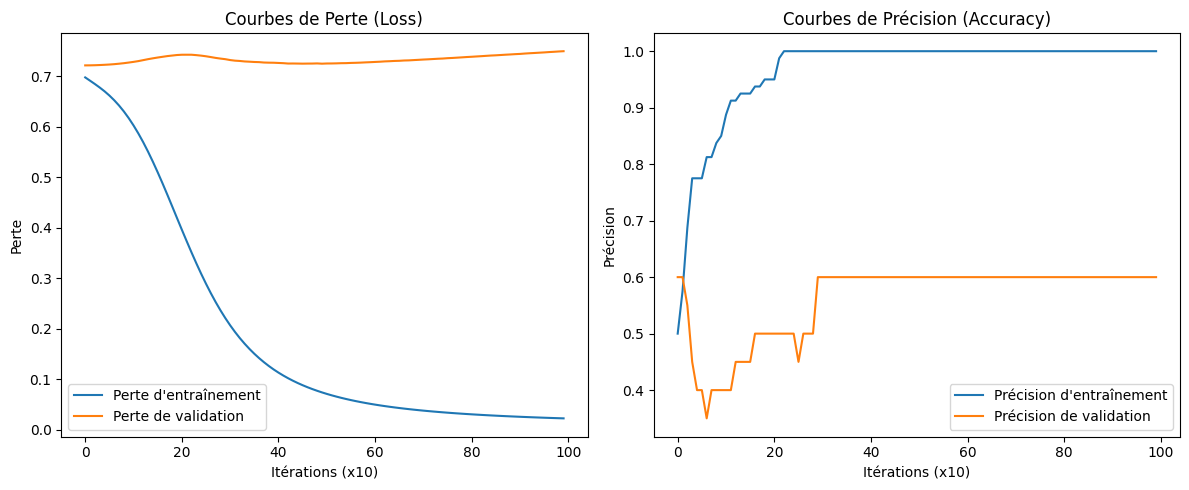

In [12]:
# --- Affichage des courbes de Loss et Accuracy ---
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_loss_hist, label='Perte d\'entraînement')
plt.plot(val_loss_hist, label='Perte de validation')
plt.legend()
plt.title('Courbes de Perte (Loss)')
plt.xlabel('Itérations (x10)')
plt.ylabel('Perte')

plt.subplot(1, 2, 2)
plt.plot(train_acc_hist, label='Précision d\'entraînement')
plt.plot(val_acc_hist, label='Précision de validation')
plt.legend()
plt.title('Courbes de Précision (Accuracy)')
plt.xlabel('Itérations (x10)')
plt.ylabel('Précision')

plt.tight_layout()
plt.show()

### Étape 3: Évaluation du Réseau de Neurones Manuel sur l'Ensemble de Validation

Nous allons maintenant évaluer les performances de notre réseau de neurones entraîné manuellement sur l'ensemble de validation. Nous calculerons la précision, afficherons un rapport de classification et une matrice de confusion. Enfin, nous créerons une animation pour visualiser les prédictions du modèle sur des images aléatoires de l'ensemble de validation.

X_val pour le réseau de neurones: (12288, 20)
y_val pour le réseau de neurones: (1, 20)
Précision du réseau de neurones manuel sur l'ensemble de validation: 60.00 %

Rapport de Classification du Réseau de Neurones :
              precision    recall  f1-score   support

       chats       0.57      0.80      0.67        10
      chiens       0.67      0.40      0.50        10

    accuracy                           0.60        20
   macro avg       0.62      0.60      0.58        20
weighted avg       0.62      0.60      0.58        20


Matrice de Confusion du Réseau de Neurones :


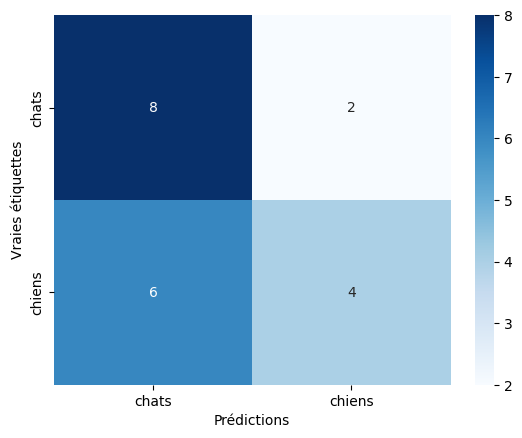

In [13]:
# Je prépare X_val_scaled et y_val dans le format (caractéristiques, échantillons) et (classes, échantillons)
X_val_nn = X_val_scaled.T
y_val_nn = y_val.reshape(1, -1)

print(f"X_val pour le réseau de neurones: {X_val_nn.shape}")
print(f"y_val pour le réseau de neurones: {y_val_nn.shape}")

# J'effectue des prédictions sur l'ensemble de validation en utilisant les paramètres entraînés
y_pred_nn = prediction(X_val_nn, parametres_entraines)

# J'affiche la précision sur l'ensemble de validation
accuracy_nn = accuracy_score(y_val_nn.flatten(), y_pred_nn.flatten())
print(f"Précision du réseau de neurones manuel sur l'ensemble de validation: {accuracy_nn*100:.2f} %")

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns # Importation de seaborn

# J'affiche le rapport de classification

print("\nRapport de Classification du Réseau de Neurones :")
# sns.heatmap(confusion_matrix(y_val_nn.flatten(), y_pred_nn.flatten()), annot=True, fmt='d', cmap='Blues', xticklabels=['chats', 'chiens'], yticklabels=['chats', 'chiens'])
print(classification_report(y_val_nn.flatten(), y_pred_nn.flatten(), target_names=['chats', 'chiens']))

# J'affiche la matrice de confusion
conf_matrix_nn = confusion_matrix(y_val_nn.flatten(), y_pred_nn.flatten())
print("\nMatrice de Confusion du Réseau de Neurones :")
sns.heatmap(conf_matrix_nn, annot=True, fmt='d', cmap='Blues', xticklabels=['chats', 'chiens'], yticklabels=['chats', 'chiens'])
plt.xlabel('Prédictions')
plt.ylabel('Vraies étiquettes')
plt.show()

#### Animation des prédictions du réseau de neurones manuel

In [14]:
from IPython.display import HTML
import matplotlib.animation as animation

# Je définis la fonction pour créer l'animation
def create_prediction_animation(X, y_true, y_pred, image_paths, label_map, model_name="Modèle"):
    fig, ax = plt.subplots(figsize=(6, 8))

    # Je vais stocker les cadres de l'animation ici
    ims = []

    # Je sélectionne 10 images aléatoires pour l'animation
    random_indices = np.random.choice(len(y_true.flatten()), 10, replace=False)

    for i in random_indices:
        img_path = image_paths[i]
        true_label_idx = y_true.flatten()[i]
        predicted_label_idx = y_pred.flatten()[i]

        # J'essaie de charger l'image
        try:
            img = plt.imread(img_path)
        except Exception as e:
            print(f"Erreur lors du chargement de l'image {img_path}: {e}")
            continue

        # Je prépare le texte pour le titre
        title_text = f"Vrai: {label_map[true_label_idx]} | Prédit par {model_name}: {label_map[predicted_label_idx]}"
        color = "green" if true_label_idx == predicted_label_idx else "red"

        # J'affiche l'image et le titre
        im = ax.imshow(img, animated=True)
        text = ax.text(0.5, 1.05, title_text, transform=ax.transAxes, ha="center", va="bottom", color=color, fontsize=12, animated=True)

        # Je retire les axes
        ax.axis('off')
        ims.append([im, text])

    # Je crée l'animation
    ani = animation.ArtistAnimation(fig, ims, interval=2000, blit=True, repeat_delay=1000)
    plt.close(fig) # Empêche l'affichage statique de la dernière image
    return ani

# J'utilise la fonction pour créer l'animation pour le réseau de neurones manuel
ani_nn = create_prediction_animation(X_val_scaled, y_val_nn, y_pred_nn, validation_image_paths, label_map, model_name="Réseau Neurones Manuel")

# J'affiche l'animation
HTML(ani_nn.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.